# S6E9 starter: how to tell a real gain from noise

*By [Georgy Mamarin](https://www.kaggle.com/georgymamarin) · [Playground Series S6E9](https://www.kaggle.com/competitions/playground-series-s6e9)*

<div align="center">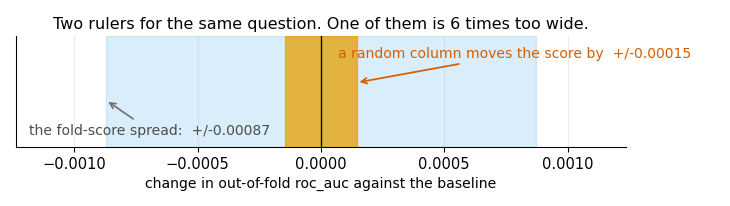</div>

<div align="center"><em>The narrow band is what a column of random numbers does to the score. Anything inside it is not a result. Section 7 measures both bands in your own session.</em></div>

You will spend this month deciding whether things helped, and most of those decisions are smaller than the
noise. So this notebook measures the noise first. In this episode, on the full data, a change under **0.00015 in
out-of-fold ROC AUC** is not evidence, because a column of random numbers put through the same pipeline moves
the score by that much. §7 measures it again in your own session, so you need not take mine on faith. The number
most people reach for instead, the spread between the fold scores, is about six times wider here, and judging a
small gain against it throws away real improvements.

Then the instrument earns its keep. The largest gain on this page is not a feature at all: it is two lines of
parameters, worth more than every feature here put together. The only reason I can rank them that way is that
everything on the page went through the same gate. §9 finds the first line, §10 the second.

Around that it does the ordinary work. It reads the data, builds a cross-validated LightGBM baseline where no
row is ever graded by a model that trained on it, and writes a submission whose schema matches
`sample_submission`.

### What you get from forking this
- A submission that runs without edits, and an out-of-fold score whose limits are written down in
  §14 rather than glossed over.
- A measured threshold for judging your own changes, instead of a feeling about them. That is §7.
- One cell, §8, where you write a feature and read a verdict against that threshold.
- Four ideas measured against it in §9, three from this data and one borrowed from the Code tab. Three
  of them do nothing. The fourth mostly turns out to be asking for a setting, and the setting is one word.
- The measurement that paid best here, in §10: what happens when the model is forbidden to combine
  columns at all. On this data that is worth more than every feature on the page put together, and it
  costs two lines of parameters.
- **The one way I know to fool that threshold**, measured in the same units, in §11.
- Where this data actually comes from, and what the generator changed on the way, in §16.
- Out-of-fold and test predictions saved as files, on the fold split this series has settled on, so you
  can stack them with someone else's without refitting anything.

### Contents
1. [The data and the task](#1)
2. [The target, and what it does to your metric](#2)
3. [Every column at a glance](#3)
4. [Train against test](#4)
5. [Which columns carry signal on their own](#5)
6. [A baseline you can trust](#6)
7. [The bar: what a meaningless column does to the score](#7)
8. [Test your own idea](#8)
9. [Four ideas, and the one that paid](#9)
10. [How much of this problem is combinations?](#10)
11. [The one way to fool this instrument](#11)
12. [Submission](#12)
13. [What the leaderboard can and cannot tell you](#13)
14. [Design choices and limitations](#14)
15. [Where to take it next](#15)
16. [Where this data actually comes from](#16)

*This notebook grows through the month. What is here already runs, and I add sections as the episode develops.*

In [ ]:
import os, glob, random, textwrap, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

SEED = 42
def seed_everything(s=SEED):
    random.seed(s); np.random.seed(s); os.environ["PYTHONHASHSEED"] = str(s)
seed_everything()

# Okabe-Ito palette: safe for the common forms of colour blindness
PALETTE = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00"]
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})

def takeaway(*lines):
    # one consistent shape for every conclusion, wrapped to the width Kaggle renders
    print()
    for l in lines:
        for part in textwrap.wrap(l, 83) or [""]:
            print("|  " + part)

def find_data(slug=""):
    # the competition's own folder first: an attached extra dataset may also ship a train.csv
    for p in [f"/kaggle/input/{slug}", f"/kaggle/input/competitions/{slug}",
              os.environ.get("LOCAL_DATA", ""), "data", "../data"]:
        if p and os.path.exists(os.path.join(p, "train.csv")):
            return p
    hits = sorted(glob.glob("/kaggle/input/**/train.csv", recursive=True))
    if hits:
        print("NOTE: falling back to", hits[0], "- check this is the competition's own train.csv")
        return os.path.dirname(hits[0])
    raise FileNotFoundError("train.csv not found. /kaggle/input holds: " + str(glob.glob("/kaggle/input/*")))

<a id="1"></a>
## 1. The data and the task

Four settings at the top of the next cell decide everything downstream. `COMP_SLUG` is the tail of the
competition's URL, and it tells the loader which input folder is the competition's own rather than an attached
dataset that happens to ship a `train.csv` too. `METRIC` is on the Evaluation tab. `TASK` is an override for the
case where the guess below gets it wrong.

`FAST` is the one to reach for while you are working. It cuts the rows, the folds and the boosting rounds, and
it cuts them for every run on the page, including the noise draws that set the bar. So a fast session still
answers "did my idea beat noise" correctly; what it cannot do is give you a number comparable to a full run, or
a submission worth uploading. The notebook says so in every place it matters.

In [ ]:
# ================= the settings you are meant to touch =================
COMP_SLUG = "playground-series-s6e9"    # the tail of the competition URL
METRIC    = "roc_auc"                    # from the Evaluation page
TASK      = "binary"                     # binary / multiclass / regression
FAST      = False                     # True while you edit: fewer rows and
                                      # folds, far quicker, not comparable
# =======================================================================

In [ ]:
DATA  = find_data(COMP_SLUG)
train = pd.read_csv(os.path.join(DATA, "train.csv"))
test  = pd.read_csv(os.path.join(DATA, "test.csv"))
samp  = pd.read_csv(os.path.join(DATA, "sample_submission.csv"))

id_col   = samp.columns[0]
sub_cols = [c for c in samp.columns if c != id_col]
assert id_col in test.columns, (f"sample_submission's id column '{id_col}' is not in test "
                                f"{list(test.columns[:4])} - name it by hand")

only_in_train = [c for c in train.columns if c not in test.columns]
target = only_in_train[0] if len(only_in_train) == 1 else sub_cols[0]
assert target in train.columns, (f"could not identify the target: train holds {only_in_train} that test "
                                 f"lacks, and '{target}' is not one of them - name it by hand")

features = [c for c in test.columns if c not in (id_col, target)]   # never the target, never the id

y_raw     = train[target]
n_classes = y_raw.nunique()
if TASK != "auto":
    task = TASK
elif n_classes == 2:
    task = "binary"
elif pd.api.types.is_numeric_dtype(y_raw) and (pd.api.types.is_float_dtype(y_raw) or n_classes > 20):
    task = "regression"
else:
    task = "multiclass"

cat_feats = [c for c in features
             if not pd.api.types.is_numeric_dtype(train[c]) or train[c].dtype == bool]
num_feats = [c for c in features if c not in cat_feats]
lowcard   = [c for c in num_feats if train[c].nunique() <= 15]   # numeric, but with few distinct values

metric = METRIC if METRIC != "auto" else \
    {"regression": "rmse", "binary": "roc_auc", "multiclass": "accuracy"}[task]
SUB_FORMAT = "per_class" if len(sub_cols) > 1 else "single"

KNOWN_METRICS = ("rmse", "rmsle", "mae", "roc_auc", "log_loss", "accuracy", "balanced_accuracy")
if metric not in KNOWN_METRICS:
    raise ValueError(f"METRIC '{metric}' is not implemented here. Known: {KNOWN_METRICS}. "
                     "Add it to score() in section 6 before going further -- otherwise every number "
                     "below would silently be a different metric.")

print(f"target        : {target}")
print(f"task          : {task}" + ("   [guessed]" if TASK == "auto" else "   [set by hand]")
      + f"   ({n_classes:,} distinct target values, dtype {y_raw.dtype})")
print(f"metric        : {metric}" + ("   [guessed]" if METRIC == "auto" else "   [set by hand]"))
print(f"submission    : {SUB_FORMAT}   ({len(sub_cols)} column(s) besides '{id_col}')")
print(f"features      : {len(features)}  =  {len(num_feats)} numeric + {len(cat_feats)} categorical")
if lowcard:
    for i, part in enumerate(textwrap.wrap("numeric but low-cardinality: " + ", ".join(lowcard), 70)):
        print(("                " if i == 0 else "                  ") + part)
print(f"train / test  : {len(train):,} / {len(test):,} rows")
if TASK == "auto" and task == "multiclass" and pd.api.types.is_integer_dtype(y_raw):
    takeaway(f"'{target}' is a whole-number column with {n_classes} distinct values, so it was read as"
             f" {task}.",
             "If this episode is judged by RMSE on a count or a rating, that guess is wrong:"
             " set TASK above by hand.")
train.head()

The target is the column `train` has and `test` does not. When `TASK` is `auto` the task is guessed from that column's dtype and
how many distinct values it holds, and the printout says whether that happened or whether you set it, and one case breaks that guess: a whole-number target with few levels, say a
rating or a count, reads as a class problem even when the episode is judged by RMSE. If the printout above
disagrees with the Evaluation page, set `TASK` and `METRIC` by hand and re-run. Everything below follows what
that cell prints.

The cell also sorts columns into numeric and categorical by dtype, not by how many distinct values they happen
to have. An integer column with twelve levels is still numeric, and that choice changes both the chart it gets
in §4 and how §5 estimates its signal.

<a id="2"></a>
## 2. The target, and what it does to your metric

The shape of the target decides how you read every score below it. Imbalance decides whether accuracy means
anything at all; skew decides whether the model is better off fitted in log space.

In [ ]:
fig, ax = plt.subplots(figsize=(7.2, 3.2))
if task == "regression":
    ax.hist(train[target], bins=60, color=PALETTE[0], alpha=0.85)
    ax.set_xlabel(target); ax.set_ylabel("rows")
    ax.set_title(f"Target '{target}': skew {train[target].skew():.2f}")
    plt.tight_layout(); plt.show()
    print(train[target].describe().round(3).to_string())
    sk = train[target].skew()
    takeaway(f"Skew is {sk:.2f}.",
             "A tail this heavy usually rewards modelling in log space. Worth testing in section 8."
             if abs(sk) > 1 else
             "Close enough to symmetric that a transform is unlikely to be the lever here.")
else:
    vc = train[target].value_counts()
    ax.bar([str(c) for c in vc.index], vc.values, color=PALETTE[:len(vc)])
    for i, v in enumerate(vc.values):
        ax.text(i, v, f"{v/len(train)*100:.1f}%", ha="center", va="bottom", fontsize=10)
    ax.set_ylabel("rows, thousands"); ax.set_xlabel(target); ax.margins(y=0.15)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}")
    ax.set_title(f"Class balance: the largest class is {vc.max()/vc.min():.1f}x the smallest")
    plt.tight_layout(); plt.show()
    rarest = vc.min() / len(train)
    takeaway(f"The rarest class is {rarest:.1%} of the rows.",
             (f"Plain accuracy means little here: always answering '{vc.index[0]}'"
              f" already scores {vc.max()/len(train):.1%}."
              if rarest < 0.10 else
              "Balanced enough that accuracy is readable, though the official metric decides."))

<a id="3"></a>
## 3. Every column at a glance

One table with what is worth knowing before you model: the type of each column, how many distinct values it
takes, and how lopsided it is. A column where almost every row shares one value gives a tree very little to
split on. A numeric column with six distinct values can be a category wearing a number's clothes, though
whether the model cares is a measurement rather than a rule, and §9 makes it.

If this episode has missing values the table shows them too, along with a check on whether the *fact* of a gap
carries signal. LightGBM learns a direction for NaN by itself, so filling gaps is not urgent; what it cannot see
is a pattern *across* columns, which is what §8 tests when there are gaps to count.

In [ ]:
rows = []
for c in features:
    vc = train[c].value_counts(normalize=True, dropna=True)
    rows.append((c, "categorical" if c in cat_feats else "numeric", f"{train[c].nunique():,}",
                 f"{train[c].isna().mean()*100:.2f}%", str(vc.index[0])[:18], f"{vc.iloc[0]:.1%}"))
dic = pd.DataFrame(rows, columns=["column", "type", "distinct", "missing", "most common", "its share"])
print(dic.to_string(index=False))

lop = dic.assign(sh=[float(x.strip("%")) for x in dic["its share"]]).sort_values("sh", ascending=False)
takeaway(f"Most lopsided column: {lop.iloc[0]['column']}, one value covers"
         f" {lop.iloc[0]['its share']} of the rows.",
         f"Numeric but low-cardinality: {', '.join(lowcard) if lowcard else 'none'}."
         + (" Those behave like categories, worth trying as such." if lowcard else ""))

miss = (train[features].isna().mean() * 100).round(2)
miss = miss[miss > 0].sort_values(ascending=False)

if not len(miss):
    print("\nNo missing values anywhere in train, so there is no gap pattern to build on.")
else:
    fig, ax = plt.subplots(figsize=(7.2, max(1.8, 0.32 * len(miss))))
    ax.barh(miss.index, miss.values, color=PALETTE[1]); ax.invert_yaxis()
    ax.set_xlabel("% of rows missing"); ax.set_title("Missing values by column (train)")
    plt.tight_layout(); plt.show()

    if task == "regression":
        rows = [(c, f"{train[c].isna().sum():,}", f"{train.loc[train[c].isna(), target].mean():.4f}",
                 f"{train.loc[train[c].notna(), target].mean():.4f}") for c in miss.index]
        tbl = pd.DataFrame(rows, columns=["column", "rows missing", "mean when missing", "mean when present"])
    else:
        top = train[target].mode()[0]
        rows = [(c, f"{train[c].isna().sum():,}",
                 f"{(train.loc[train[c].isna(), target] == top).mean():.4f}",
                 f"{(train.loc[train[c].notna(), target] == top).mean():.4f}") for c in miss.index]
        tbl = pd.DataFrame(rows, columns=["column", "rows missing",
                                          f"P({target}={top}) when missing", "when present"])
    print(tbl.to_string(index=False))
    gapv = (tbl.iloc[:, 2].astype(float) - tbl.iloc[:, 3].astype(float)).abs()
    w = int(gapv.idxmax())
    takeaway(f"Widest gap: '{tbl.iloc[w, 0]}', {gapv[w]:.4f} across {tbl.iloc[w, 1]} missing rows.",
             "One number with no interval around it, so read it as a place to look.",
             "Section 8 is where an idea actually gets tested.")

<a id="4"></a>
## 4. Train against test

Playground data is generated once and then split, so the two halves usually agree closely. Checking is cheap,
and in the episode where they do disagree, validation quietly lies for everyone who skipped it.

The panel eyeballs a sample of columns, and eyeballing is all it does: both sides are clipped to the 1st and
99th percentiles of train, so a heavier tail in test gets squashed into the edge bins. The two lines under it
are the part that does not need an eye: which categories turn up in test that train never saw, and the column
whose missing rate differs most between the two files.

In [ ]:
show = [c for pair in zip(num_feats + [None] * len(cat_feats), cat_feats + [None] * len(num_feats))
        for c in pair if c is not None][:8]          # interleave, so categoricals are never crowded out

if show:
    ncol = 2; nrow = int(np.ceil(len(show) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(7.6, 1.9 * nrow))
    flat = np.atleast_1d(axes).ravel()
    for ax, f in zip(flat, show):
        if f in cat_feats:
            a = train[f].value_counts(normalize=True)
            b = test[f].value_counts(normalize=True)
            keys = sorted(set(a.index) | set(b.index), key=str)[:12]   # union: test-only levels stay visible
            x = np.arange(len(keys))
            ax.bar(x - 0.2, a.reindex(keys).fillna(0).values, 0.4, color=PALETTE[0], label="train")
            ax.bar(x + 0.2, b.reindex(keys).fillna(0).values, 0.4, color=PALETTE[1], label="test")
            # cutting at a fixed width turns "Hatchback" into "Hatchbac", which reads as a bug
            short = [str(v) if len(str(v)) <= 11 else str(v)[:10] + "." for v in keys]
            ax.set_xticks(x); ax.set_xticklabels(short, fontsize=8, rotation=30)
        else:
            lo, hi = train[f].quantile([0.01, 0.99])
            # a column with few distinct values is not a histogram: 40 bins on 4 values draws needles
            nun = train[f].nunique()
            bins = min(40, max(nun, 2))
            # weights rather than density so every panel on the grid reads as a share of rows
            for fr, col, lab in ((train, PALETTE[0], "train"), (test, PALETTE[1], "test")):
                v = fr[f].clip(lo, hi)
                ax.hist(v, bins=bins, alpha=0.55, color=col, label=lab,
                        weights=np.full(len(v), 1 / len(v)))
            if nun <= 12:
                ax.set_xticks(sorted(train[f].dropna().unique())[:12])
        ax.set_title(f, fontsize=10); ax.tick_params(labelsize=8)
    for ax in flat[len(show):]: ax.axis("off")
    # the legend goes on the figure: inside a panel it sat on top of the bars it was explaining
    h, l = flat[0].get_legend_handles_labels()
    fig.legend(h, l, fontsize=8, ncol=2, loc="upper right", frameon=False,
               bbox_to_anchor=(0.99, 0.995))
    fig.suptitle("train against test. Every panel is a share of that frame's rows.",
                 fontsize=10, x=0.02, ha="left")
    plt.tight_layout(); plt.show()

unseen = {c: sorted(set(test[c].dropna().unique()) - set(train[c].dropna().unique()))[:5]
          for c in cat_feats}
unseen = {c: v for c, v in unseen.items() if v}
miss_rate = pd.DataFrame({"train %": (train[features].isna().mean() * 100).round(2),
                          "test %":  (test[features].isna().mean() * 100).round(2)})
miss_rate["gap"] = (miss_rate["train %"] - miss_rate["test %"]).abs()
worst = miss_rate.sort_values("gap", ascending=False).head(3)

print(f"columns shown above: {len(show)} of {len(features)}")
takeaway(("Categories present in test but never in train: " + ", ".join(f"{c}={v}" for c, v in unseen.items())
          if unseen else "No category appears in test that is absent from train."),
         (f"Largest train/test difference in missing rate: {worst.index[0]} "
          f"({worst['train %'].iloc[0]:.2f}% against {worst['test %'].iloc[0]:.2f}%)."
          if miss_rate["gap"].max() > 0 else "Missing rates are identical in train and test."))

<a id="5"></a>
## 5. Which columns carry signal on their own

Mutual information asks what each column tells you about the target by itself. It misleads in both directions,
and the second one is the expensive mistake:

- a column can rank high because it stands in for something the model already has, and add nothing once that is in;
- a column can rank at zero and still be decisive **in combination** with another, because mutual information
  never looks at pairs.

So this chart is a reading order, not a shortlist. §16 opens the published literature on this subject and
explains why checking this order against it would prove nothing either way. One implementation detail worth knowing: missing values are
filled with a sentinel before the estimate, so part of a column's score can come from *where* it is missing
rather than from its values.

In [ ]:
from sklearn.feature_selection import mutual_info_classif, mutual_info_regression

Xmi = train[features].copy()
for c in cat_feats:
    Xmi[c] = Xmi[c].astype("category").cat.codes
Xmi = Xmi.fillna(-999)

mi_fn = mutual_info_regression if task == "regression" else mutual_info_classif
mi = pd.Series(mi_fn(Xmi, train[target], discrete_features=[c in cat_feats for c in features],
                     random_state=SEED), index=features).sort_values()

fig, ax = plt.subplots(figsize=(7.2, max(2.2, 0.30 * len(mi))))
ax.barh(mi.index, mi.values, color=[PALETTE[3] if f in cat_feats else PALETTE[0] for f in mi.index])
# the note lives in the axis label: as a floating annotation it landed on the legend
ax.set_xlabel("mutual information with the target, in nats\n"
              "a tick at the axis is a measured zero, not a missing value", fontsize=10)
ax.set_title("Single-column signal")
# a zero-length bar is indistinguishable from a missing one, so every row gets a visible stub
for i, v in enumerate(mi.values):
    if v <= mi.max() * 0.004:
        ax.plot(mi.max() * 0.004, i, "|", color="0.45", ms=9)
if cat_feats:      # a legend, not a colour promise in the title: a zero-length bar is invisible
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(color=PALETTE[0], label="numeric"), Patch(color=PALETTE[3], label="categorical")],
              fontsize=9, loc="lower right")
plt.tight_layout(); plt.show()

top3 = list(mi.sort_values(ascending=False).index[:3])
zeros = list(mi[mi <= 1e-4].index)
takeaway(f"Strongest on their own: {', '.join(top3)}.",
         (f"At or near zero: {', '.join(zeros)}."
          "  Try them in a ratio with a strong column before writing them off." if zeros else
          "No column sits at zero, so nothing here is obviously dead weight."))

<a id="6"></a>
## 6. A baseline you can trust

LightGBM on a K-fold split, stratified when the target is a class and every class has at least as many rows as
there are folds, plain K-fold otherwise. Scored on out-of-fold predictions, so no row is in the training set of
the model that grades it, with the caveat §14 spells out. Categorical columns go in natively, and the only
mapping applied to them is a label code shared by train and test, so nothing derived from the target is
computed outside the fold.

The parameters are fixed sensible values that were not tuned for this episode. That is deliberate: an untuned
floor is the honest thing to measure improvements against. `FAST` from §1 lands here, setting the fold count,
the round cap and the size of the row sample that every run shares.

The whole loop lives in one function, `run_cv()`, which every section after it calls again with different inputs. Its cell
is folded to keep the page readable; open it here, or fork the notebook and read it in the editor. Three cells are left open on the page: the settings in §1, the feature
cell in §8, and the single line in §12 that picks what gets submitted. Those are the ones you are meant to
change.

In [ ]:
import time
from sklearn.model_selection import StratifiedKFold, KFold
from sklearn.metrics import (roc_auc_score, accuracy_score, balanced_accuracy_score,
                             mean_squared_error, log_loss)
import lightgbm as lgb

if task == "regression":
    y = train[target].to_numpy(dtype=float); n_out = 1; le = None
    objective = dict(objective="regression", metric="rmse")
else:
    from sklearn.preprocessing import LabelEncoder
    le = LabelEncoder(); y = le.fit_transform(train[target]); n_out = len(le.classes_)
    objective = (dict(objective="binary") if task == "binary"
                 else dict(objective="multiclass", num_class=n_out))

# FAST changes three things at once, and it changes them for EVERY run in this notebook, the noise
# draws included. That is the point: comparisons inside one setting stay honest, and only the
# absolute numbers move. The row subsample is drawn once here and reused, so every run sees the
# same rows.
FOLDS     = 3 if FAST else 5
ROUNDS    = 400 if FAST else 1500
FAST_ROWS = 150_000
ROWS = (np.random.default_rng(SEED).choice(len(train), min(FAST_ROWS, len(train)), replace=False)
        if FAST else np.arange(len(train)))
TR, Y = train.iloc[ROWS].reset_index(drop=True), y[ROWS]
if FAST:
    print(f"FAST is on: {len(TR):,} of {len(train):,} rows, {FOLDS} folds, {ROUNDS} rounds.")
    print("Numbers below are NOT comparable to a full run. They are comparable to each other,")
    print("because the bar in section 7 is measured under exactly the same setting.")

PARAMS = dict(**objective, learning_rate=0.05, num_leaves=63, feature_fraction=0.8,
              bagging_fraction=0.8, bagging_freq=1, min_child_samples=50,
              verbose=-1, num_threads=os.cpu_count())
LOWER_IS_BETTER = metric in ("rmse", "rmsle", "mae", "log_loss")

def score(y_true, p):
    # p: probabilities for classification, values for regression
    if metric == "rmse":              return mean_squared_error(y_true, p) ** 0.5
    if metric == "rmsle":             return mean_squared_error(np.log1p(np.clip(y_true, 0, None)),
                                                                np.log1p(np.clip(p, 0, None))) ** 0.5
    if metric == "mae":               return float(np.abs(y_true - p).mean())
    if metric == "roc_auc":
        if p.ndim > 1 and p.shape[1] > 2:
            return roc_auc_score(y_true, p, multi_class="ovr", average="macro",
                                 labels=list(range(n_out)))
        return roc_auc_score(y_true, p[:, 1] if p.ndim > 1 else p)
    if metric == "log_loss":
        pp = p if p.ndim > 1 else np.column_stack([1 - p, p])
        return log_loss(y_true, pp, labels=list(range(n_out)))
    hard = p.argmax(1) if p.ndim > 1 else (p >= 0.5).astype(int)
    if metric == "balanced_accuracy": return balanced_accuracy_score(y_true, hard)
    return accuracy_score(y_true, hard)

def run_cv(make=None, label="baseline", n_folds=None, rounds=None, seed=None, log=True,
           fold_make=None, extra=None, params=None):
    n_folds = FOLDS if n_folds is None else n_folds
    rounds  = ROUNDS if rounds is None else rounds
    seed = SEED if seed is None else seed        # read at call time, so changing SEED moves everything
    # extra: a frame of labelled rows to TRAIN on and never grade. They ride at the end, join the
    # training part of every fold, and take no part in the split or the score.
    # make(df) -> df runs ONCE on train and ONCE on test, before the folds are cut: row-wise only.
    # fold_make(Xtr, ytr) -> put(df) -> df is the other hook. It is called inside every fold with
    # that fold's TRAINING rows only, and the returned `put` is applied to train, validation and
    # test. Anything fitted on the target belongs here, not in make(). Section 11 shows why.
    # params overrides PARAMS for this run only, for testing a setting rather than a feature.
    A, B = TR[features].copy(), test[features].copy()
    YY, n_graded = Y, len(A)
    if extra is not None:
        missing = [c for c in features + [target] if c not in extra.columns]
        assert not missing, f"`extra` has no {missing}; it needs every feature and the target"
        A = pd.concat([A, extra[features]], ignore_index=True)
        YY = np.concatenate([Y, extra[target].to_numpy(dtype=float) if task == "regression"
                             else le.transform(extra[target])])
    if make is not None:
        n_before = len(A)
        A, B = make(A), make(B)
        assert list(A.columns) == list(B.columns), "make() returned different columns for train and test"
        assert len(A) == n_before and len(B) == len(test), \
            "make() changed the row count. To add training rows, pass them as extra=."

    # a column counts as categorical if EITHER frame is non-numeric; going through object means a
    # dtype mismatch between train and test (a column all-NaN in one of them) cannot raise
    for c in [c for c in A.columns
              if not (pd.api.types.is_numeric_dtype(A[c]) and pd.api.types.is_numeric_dtype(B[c]))]:
        # levels become text: LightGBM cannot serialise interval, date or tuple categories, and
        # binning a column with pd.cut inside make() is the most likely first edit anyone makes
        a = A[c].astype(str).where(A[c].notna()); b = B[c].astype(str).where(B[c].notna())
        u = pd.api.types.union_categoricals([pd.Categorical(a), pd.Categorical(b)]).categories
        A[c] = pd.Categorical(a, categories=u); B[c] = pd.Categorical(b, categories=u)
        if a.notna().any() and b.notna().any() and not (set(a.dropna()) & set(b.dropna())):
            print(f"WARNING: '{c}' shares no level between train and test. A feature built with pd.cut"
                  " is binned separately in each frame, so the model cannot use it on test.")

    stratify = task != "regression" and np.unique(Y, return_counts=True)[1].min() >= n_folds
    sp = (StratifiedKFold(n_folds, shuffle=True, random_state=seed) if stratify
          else KFold(n_folds, shuffle=True, random_state=seed))
    oof  = np.zeros(n_graded) if task in ("regression", "binary") else np.zeros((n_graded, n_out))
    pred = np.zeros(len(B)) if task in ("regression", "binary") else np.zeros((len(B), n_out))
    fold_id, folds, used, t0 = np.full(n_graded, -1, dtype=int), [], [], time.time()
    for k, (itr, iva) in enumerate(sp.split(np.arange(n_graded), Y if stratify else None), 1):
        itr = np.concatenate([itr, np.arange(n_graded, len(A))])   # the extra rows train in every fold
        Xtr, Xva, Xte = A.iloc[itr], A.iloc[iva], B
        if fold_make is not None:
            put = fold_make(Xtr, YY[itr])         # fitted on this fold's training rows and nothing else
            Xtr, Xva, Xte = put(Xtr), put(Xva), put(Xte)
            assert list(Xtr.columns) == list(Xte.columns), "fold_make gave train and test different columns"
        m = lgb.train(dict(PARAMS, seed=seed, **(params or {})),
                      lgb.Dataset(Xtr, YY[itr]), num_boost_round=rounds,
                      valid_sets=[lgb.Dataset(Xva, Y[iva])],
                      callbacks=[lgb.early_stopping(75, verbose=False)])
        oof[iva] = m.predict(Xva); pred += m.predict(Xte) / n_folds; fold_id[iva] = k
        used.append(m.best_iteration or rounds)
        folds.append(score(Y[iva], oof[iva]))
        if log: print(f"  fold {k}: {metric} = {folds[-1]:.5f}   (stopped at {m.best_iteration} rounds)")
    r = dict(label=label, oof=oof, pred=pred, folds=np.array(folds), score=score(Y, oof),
             rounds=float(np.mean(used)),
             spread=float(np.std(folds, ddof=1)), fold_id=fold_id, seconds=time.time() - t0)
    if log:
        print(f"{label}: OOF {metric} = {r['score']:.5f}   [{r['seconds']:.0f}s]")
    return r

base = run_cv(label="baseline")
takeaway(f"Baseline OOF {metric} = {base['score']:.5f}, in {base['seconds']:.0f} seconds.",
         "That is the number every idea below is measured against.",
         "It is not a bar yet: section 7 measures how far it moves on its own.")

<a id="7"></a>
## 7. The bar: what a meaningless column does to the score

How much does the score move when you change **nothing that matters**? Until you have that number, no
comparison below it means very much.

The number closest to hand is how much the fold scores differ from each other, and it is far too wide for the
job. Each fold score is computed on one fold's worth of rows, so it mostly measures which
rows landed in which fold rather than how much the pooled out-of-fold score wanders. (Where this notebook prints
a number for it, that number is the standard deviation of the fold scores, not their range.)

The direct answer costs two more runs. Add a column of uniform random numbers, which by construction knows
nothing about the target, and put it through exactly the same pipeline. Whatever it moves the score by is
movement that means nothing.

Turn `FAST` on and this number is measured again under that setting, where it comes out wider, because a score
computed on fewer rows is a noisier score. That is the whole reason it is re-measured rather than carried over:
a bar borrowed from a bigger run would wave through changes that are pure noise at the size you are working at.

It does move the score, and usually downwards. The obvious explanation is `feature_fraction=0.8`: a useless
column takes up room in the column subsample and displaces one that carries signal. I tested that by re-running
everything at `feature_fraction=1.0`, where there is no subsample to crowd. The penalty shrank, from about
0.00013 to about 0.00008 averaged over two draws each, but it did not go away. So the subsample explains part of
it at most. A useless column also gives every tree one more split candidate to waste, and it moves where early
stopping lands.

In [ ]:
def noise_column(seed):
    def make(df):
        out = df.copy()
        out["_noise"] = np.random.default_rng(seed).random(len(df))
        return out
    return make

nulls = [run_cv(noise_column(101), label="pure noise A", log=False),
         run_cv(noise_column(202), label="pure noise B", log=False)]

rows = []
for r in [base] + nulls:
    d = (base["score"] - r["score"]) if LOWER_IS_BETTER else (r["score"] - base["score"])
    w = ((base["folds"] - r["folds"]) if LOWER_IS_BETTER else (r["folds"] - base["folds"]))
    rows.append((r["label"], f"{r['score']:.5f}", "reference" if r is base else f"{d:+.5f}",
                 "-" if r is base else f"{int((w > 0).sum())}/{len(w)}", f"{r['seconds']:.0f}s"))
print(pd.DataFrame(rows, columns=["run", f"OOF {metric}", "change", "folds up", "time"]).to_string(index=False))

BAR = max(abs(n["score"] - base["score"]) for n in nulls)
print(f"\nsd of the {len(base['folds'])} fold scores in the baseline run : {base['spread']:.5f}")
print(f"movement from a column of pure noise: {BAR:.5f}")
takeaway(f"The bar is {BAR:.5f}. A change smaller than that is not evidence of anything.",
         (f"The fold scores have an sd of {base['spread']:.5f}, much wider."
          "  Using that as a bar would throw away real gains."
          if BAR < base["spread"] else
          f"Unusually, the sd of the fold scores ({base['spread']:.5f}) is no wider than the bar."
          "  Both are noisy on small data, so add more draws before trusting either."),
         f"It is the largest of {len(nulls)} draws, so it is a conservative gate, and it creeps "
         f"upward if you add more: the maximum of a sample grows with the sample. To sharpen it, add "
         f"draws and read their spread rather than their maximum.",
         "Both draws came out negative, so this is really how far down a meaningless column drags "
         "the score. Used against a gain it errs on the side of not believing you, which is the "
         "side to err on.")

<a id="8"></a>
## 8. Test your own idea

This is the cell everything else was wired up for. There is exactly one line marked `TWEAK THIS`, it always
runs, and the verdict is printed by the same cell, so a re-run can never leave a stale answer on the screen
next to fresh code. Write your feature, run the cell, read the verdict against the bar from §7.

`my_features` runs once on train and once on test, before the folds are cut. Keep it row-wise, for two separate
reasons. Anything that reads the target leaks. And anything that aggregates over rows (counts, group means,
ranks, quantile bins) gets fitted on the whole of train including the rows it will be scored on, and on a
different population for test than for train.

The placeholder adapts to the data: how many values a row is missing at once when there are gaps, otherwise the
ratio of the two strongest *numeric* columns by the §5 ranking. Categoricals are skipped there, so that pair
need not be the top two names §5 printed. Either way it is a stand-in for something §3 and §5 suggest for this
episode. Which one you got is printed above the function, and the choice is made outside it, so replacing the
marked line replaces the whole feature.

In [ ]:
# the placeholder picks itself from section 5; both names come from `mi`
_by_mi = [c for c in mi.sort_values(ascending=False).index if c in num_feats]
MI_TOP, MI_2ND = (_by_mi + [None, None])[:2]
GAPS    = train[features].isna().any().any()
EXAMPLE = "n_missing" if (GAPS or MI_2ND is None) else "ratio"
print(f"placeholder feature: {EXAMPLE}"
      + (f"  ({MI_TOP} / {MI_2ND})" if EXAMPLE == "ratio" else ""))

# resolved outside the function, so the marked line is the only one
PLACEHOLDER = ((lambda df: df.isna().sum(axis=1)) if EXAMPLE == "n_missing"
               else (lambda df: df[MI_TOP] / df[MI_2ND].abs().clip(1e-9)))

def my_features(df):
    out = df.copy()
    out["my_feature"] = PLACEHOLDER(df)        # <-- TWEAK THIS
    return out

cand = run_cv(my_features, label="my idea")

sign     = -1 if LOWER_IS_BETTER else 1
gain     = sign * (cand["score"] - base["score"])
per_fold = sign * (cand["folds"] - base["folds"])
wins     = int((per_fold > 0).sum())
ties     = int((per_fold == 0).sum())

print(f"\nbaseline  {base['score']:.5f}")
print(f"my idea   {cand['score']:.5f}     change {gain:+.5f}")
print(f"bar from section 7: {BAR:.5f}")
print(f"folds up: {wins}/{len(per_fold)}" + (f" ({ties} tied)" if ties else ""))
print("per fold: " + "  ".join(f"{d:+.5f}" for d in per_fold))
print()
if ties == len(per_fold):
    print("VERDICT: identical to the baseline, fold for fold.")
    print("         The feature changed nothing. Check it is not constant:")
    print("         a column of zeros is the usual accident.")
elif gain <= 0:
    print("VERDICT: no gain. The idea does nothing, or it hurts.")
    print("         The same rule applies downwards: a small negative")
    print("         is not proof of harm either.")
elif gain > BAR:
    print("VERDICT: larger than a column of pure noise. Worth keeping.")
    print("         To submit it, set FINAL = cand in section 12.")
elif wins + ties == len(per_fold):
    k = len(per_fold); shared = (k - 2) / (k - 1)
    print(f"VERDICT: below the bar, but no fold got worse. Under an ideal")
    print(f"         null, {wins} folds agreeing is 1-in-{2 ** wins}. Two")
    print(f"         training folds share {shared:.0%} of their")
    print("         rows, so the real odds are worse. Re-run both sides")
    print("         on a new seed first.")
else:
    print("VERDICT: inside the noise band and not consistent across")
    print("         folds. Nothing to see yet.")

**To check a borderline result**, move *everything* to the new folds, not just the candidate. The clean way is
one line: set `SEED = 7` and re-run §6, §7 and §8 in order. `run_cv` reads `SEED` when it is called, so the
baseline, both noise draws and your candidate all land on the same new folds. Changing the seed for the
candidate alone leaves `BAR` measured on the old folds, and the verdict cell will happily print a number for
that comparison anyway. One side effect worth knowing: `base` is what §12 submits, so overwriting it changes
`submission.csv`.

<a id="9"></a>
## 9. Four ideas, and the one that paid

Three of these come from the data. The table in §3 shows two columns clipped at their minimum: 9.2% of rows sit
exactly at an income of 30000, and 21.6% sit exactly at a commute of 5 km. The §4 panel puts test beside train on those columns, and they
sit on top of each other, so this is how the data was generated rather than a quirk of one split. §3 also flags three numeric columns with very
few distinct values, and §16 hands over a prior from the published literature: the two strongest influences are
supposed to matter in combination, which is the one thing mutual information cannot see.

The fourth comes from the Code tab. Several notebooks in this competition split each number into its decimal
digits and hand those to the model as separate columns. That is a trick without a reason attached, which is
precisely what the gate is for.

The cell below is the pattern for trying several at once: open it, put a function in `IDEAS`, run it, and read
the verdict column.

One caveat before the numbers. The bar is the larger of two noise draws, so if an idea's change is exchangeable
with those, it comes out on top one time in three by chance alone. Four ideas against a bar built from two draws
is a loose gate, and any of them landing just outside it would need a second seed before I believed it. The one
that does clear it here clears it by a distance where that stops mattering.

In [ ]:
# the floors are found once, on train, OUTSIDE make() - section 14 explains why that matters
# a pile of rows sitting exactly on the minimum only means clipping when the column is otherwise
# continuous: on a four-level count column the lowest level is just the lowest level
_cont  = [c for c in num_feats if train[c].nunique() > 50]
_share = {c: float((train[c] == train[c].min()).mean()) for c in _cont}
FLOORS = {c: train[c].min() for c, sh in sorted(_share.items(), key=lambda kv: -kv[1])[:2] if sh > 0.05}
print("clipped floors found:", {c: float(v) for c, v in FLOORS.items()})

def as_text(col):
    return col.astype(str).where(col.notna())        # keep NaN as NaN, not as the string "nan"

def floor_flags(df):
    out = df.copy()
    for c, v in FLOORS.items():
        out[f"at_{c}_floor"] = (df[c] == v).astype(int)
    return out

def lowcard_as_categorical(df):
    out = df.copy()
    for c in lowcard:
        out[c] = as_text(out[c])
    return out

# the prior from section 16: the published work says the top two influences matter in interaction,
# and mutual information cannot see pairs. TOP2 are this data's two strongest columns.
TOP2 = list(mi.sort_values(ascending=False).index[:2])

def literature_interaction(df):
    out = df.copy()
    a, b = TOP2
    ca = df[a] if pd.api.types.is_numeric_dtype(df[a]) else df[a].astype("category").cat.codes
    cb = df[b] if pd.api.types.is_numeric_dtype(df[b]) else df[b].astype("category").cat.codes
    pair = ca.astype(str) + "|" + cb.astype(str)
    out["top2_interaction"] = pair.where(df[a].notna() & df[b].notna())   # after a join, no value is NaN
    return out

# the fourth idea is not from this data at all. Several public notebooks in this competition add the
# decimal digits of a number as separate columns, (x // 10**k) % 10, and it is worth measuring rather
# than copying. WIDEST is the numeric column with the most distinct values, which is where it pays.
WIDEST = max(num_feats, key=lambda c: train[c].nunique()) if num_feats else None

def _digit(v, k):                          # magnitude only, so a negative column does not get two encodings
    return (v.abs() // (10.0 ** k) % 10).where(v.notna())

# which digits to build is decided ONCE, on train. Deciding it inside the function would give train
# and test different column lists whenever a digit is constant in one frame and not the other.
DIGIT_KS = ([k for k in range(len(str(int(abs(train[WIDEST]).max()))))
             if _digit(train[WIDEST], k).nunique() > 1] if WIDEST is not None else [])

def digits_of_widest(df):
    out = df.copy()
    for k in DIGIT_KS:
        out[f"{WIDEST}_digit{k}"] = _digit(df[WIDEST], k)
    return out

IDEAS = {"flag the clipped floors": floor_flags,          # <-- ADD YOUR OWN HERE
         "low-cardinality as categorical": lowcard_as_categorical,
         "the section 16 interaction": literature_interaction}
if DIGIT_KS:
    IDEAS[f"decimal digits of {WIDEST}"] = digits_of_widest

rows, idea_results, results = [], [], {}
for name, fn in IDEAS.items():
    r  = run_cv(fn, label=name, log=False)
    g  = (base["score"] - r["score"]) if LOWER_IS_BETTER else (r["score"] - base["score"])
    pf = (base["folds"] - r["folds"]) if LOWER_IS_BETTER else (r["folds"] - base["folds"])
    w, t = int((pf > 0).sum()), int((pf == 0).sum())
    idea_results.append((name, g)); results[name] = r
    rows.append((name, f"{r['score']:.5f}", f"{g:+.5f}", f"{w}/{len(pf)}",
                 "clears the bar" if g > BAR else
                 "identical" if t == len(pf) else
                 "no fold worse" if w + t == len(pf) else
                 "no fold better" if w == 0 else "inside the noise",
                 f"{r['seconds']:.0f}s"))
print(f"baseline {base['score']:.5f}   bar {BAR:.5f}\n")
print(pd.DataFrame(rows, columns=["idea", f"OOF {metric}", "change", "folds up", "verdict",
                                  "time"]).to_string(index=False))
print("\nkept in `results`; to submit one of them, set FINAL = results['<the idea>'] in section 12")
spent = base["seconds"] + sum(n["seconds"] for n in nulls) + cand["seconds"] + sum(
    float(r[5][:-1]) for r in rows)
n_runs = 2 + len(nulls) + len(rows)                # baseline, your idea, the noise draws, these
takeaway(f"{n_runs} cross-validation runs so far, {spent:.0f} seconds of CPU on this session, "
         f"and the capacity cell below, section 10 and section 11 add seven more.",
         "If you are iterating and want this quicker, lower ROUNDS in section 6 rather than removing "
         "ideas: the next cell looks up the digit idea by name, and section 10 reads the bin cap "
         "from it, so a shortened list breaks both.")

The fourth idea is the interesting one, and it is worth asking where it comes from before copying it. Decimal
digits are a function of the number, so they carry no information the model did not already hold. That leaves
two ways they can still help, and the two call for different responses.

A gradient booster does not split on values, it splits on bin edges, and `max_bin` caps how many edges a column
may have. The default cap is 255. A column with fewer distinct values than that gets a bin each and loses
nothing; a column with many more has to share, and whatever sits inside a bin becomes invisible. That is the
first way, and a setting fixes it, not a feature. The second way is that a digit is a repeating
pattern, and an axis-aligned split cannot express one cheaply at any resolution, so the columns hand the model a
shape it could not cut for itself.

Two marginal numbers cannot tell those apart. Running the cap and the feature together can, so the cell below
does that, and it asks LightGBM how many bins it actually built, since the cap is not always reached.

In [ ]:
MB = PARAMS.get("max_bin", 255)

def bins_built(cols, mb):
    # ask LightGBM rather than work it out: it adds a bin for zero when a column has none, and
    # min_data_in_bin and the construction sample stop it reaching the ceiling on a wide column
    try:
        ds = lgb.Dataset(TR[cols], params=dict(PARAMS, max_bin=mb), free_raw_data=False).construct()
        return {c: ds.feature_num_bin(i) for i, c in enumerate(cols)}
    except Exception:
        return {c: min(TR[c].nunique(), mb) for c in cols}      # older LightGBM: fall back to the cap

built = bins_built(num_feats, MB)
print(f"max_bin is {MB}: a ceiling on the bins a column may have. The count below is the"
      f"\none LightGBM actually built, not one worked out from that ceiling.\n")
print(f"{'column':<34}{'distinct values':>17}{'bins built':>12}{'values per bin':>16}")
# a column at 1.0 fits inside the cap; anything above it is sharing bins and losing resolution
for c in sorted(num_feats, key=lambda c: -TR[c].nunique()):
    n = TR[c].nunique()
    # an empty bin is not a bin with values in it, so the denominator cannot exceed the value count
    share = f"{n / min(built[c], n):.1f}"        # 1.0 means the column fits and nothing had to share
    print(f"{c:<34}{n:>17,}{built[c]:>12,}{share:>16}")

top = int(min(65535, max(MB * 2, TR[WIDEST].nunique()))) if WIDEST is not None else 0
if top > MB and DIGIT_KS:
    cap  = run_cv(label=f"max_bin={top}", params=dict(max_bin=top), log=False)
    both = run_cv(digits_of_widest, label="both", params=dict(max_bin=top), log=False)
    results[f"max_bin={top}"] = cap; results["digits and a raised cap"] = both
    after = bins_built(num_feats, top)
    print(f"\nRaising the cap to {top:,} takes {WIDEST} from {built[WIDEST]:,} bins to "
          f"{after[WIDEST]:,},\nagainst {TR[WIDEST].nunique():,} distinct values. The cap is a "
          f"ceiling, not a promise.")

    g = lambda r: (base["score"] - r["score"]) if LOWER_IS_BETTER else (r["score"] - base["score"])
    dig = dict(idea_results)[f"decimal digits of {WIDEST}"]
    rows2 = [("the digit columns, cap left alone", results[f"decimal digits of {WIDEST}"]["score"], dig),
             (f"max_bin = {top}, no new column",   cap["score"],  g(cap)),
             ("both together",                     both["score"], g(both))]
    print(f"\nbaseline {base['score']:.5f}   bar {BAR:.5f}\n")
    print(pd.DataFrame([(n, f"{sc:.5f}", f"{gg:+.5f}", f"{gg / BAR:+.1f}") for n, sc, gg in rows2],
                       columns=["change", f"OOF {metric}", "against baseline", "in bars"]
                       ).to_string(index=False))
    left = g(both) - g(cap)                 # what the digits still buy once the model has the bins
    takeaway(f"The cap alone is worth {g(cap)/BAR:+.1f} bars against {dig/BAR:+.1f} for the digit "
             f"columns, and the two overlap: together they come to {g(both)/BAR:+.1f}, not the "
             f"{(dig + g(cap))/BAR:+.1f} you would get if they were separate findings.",
             f"What the digits still add on top of the cap is {left/BAR:+.1f} bars, so they are not "
             f"only a workaround: a digit is a repeating pattern, and no number of bins lets an "
             f"axis-aligned split express one cheaply."
             if left > BAR else
             f"On top of the cap the digits add {left/BAR:+.1f} bars, inside the bar, so here they "
             f"were only a way of asking for resolution.",
             "Either way the cap is one word and the feature is a function you then maintain. Check "
             "it against the distinct-value count before engineering around a column.")
elif top <= MB:
    print("\nNo numeric column holds more distinct values than the cap, so there is nothing to "
          "recover this way.")

In [ ]:
def ruler_chart(save=None):
    # the first-screen figure: the two rulers, and how far apart they are
    sd = base["spread"]
    fig, ax = plt.subplots(figsize=(7.6, 2.15))
    ax.axvspan(-sd, sd, color=PALETTE[4], alpha=0.22)
    ax.axvspan(-BAR, BAR, color=PALETTE[1], alpha=0.75)
    ax.axvline(0, color="black", lw=1)
    ax.set_xlim(-sd * 1.42, sd * 1.42); ax.set_ylim(0, 1); ax.set_yticks([])
    ax.set_xlabel(f"change in out-of-fold {metric} against the baseline", fontsize=10.5)
    ax.set_title(f"Two rulers for the same question. One of them is {sd / BAR:.0f} times too wide.",
                 fontsize=12)
    ax.annotate(f"a random column moves the score by  +/-{BAR:.5f}", xy=(BAR, 0.58),
                xytext=(sd * 0.08, 0.84), fontsize=10.5, color=PALETTE[5], va="center",
                arrowprops=dict(arrowstyle="->", color=PALETTE[5], lw=1.3, shrinkB=2))
    ax.annotate(f"the fold-score spread:  +/-{sd:.5f}", xy=(-sd, 0.42),
                xytext=(-sd * 1.36, 0.15), fontsize=10.5, color="0.30", va="center",
                arrowprops=dict(arrowstyle="->", color="0.45", lw=1.3, shrinkB=2))
    plt.tight_layout()
    if save:
        fig.savefig(save, dpi=730 / 7.6, facecolor="white"); plt.close(fig)
    else:
        plt.show()

def noise_chart(save=None, dump=None):
    sign = -1 if LOWER_IS_BETTER else 1
    rulers = [(f"pure noise {chr(65 + i)}", sign * (n["score"] - base["score"]))
              for i, n in enumerate(nulls)]
    tried  = [("your idea, section 8", gain)] + idea_results
    measured = rulers + tried
    sd   = base["spread"]
    vals = [v for _, v in measured]
    ypos = list(range(len(measured), 0, -1))
    beat = sum(v > BAR for _, v in tried)          # one-sided: losing by more than the bar is not a win

    fig, ax = plt.subplots(figsize=(7.6, 0.46 * len(measured) + 3.0))
    ax.axvspan(-sd, sd, color=PALETTE[4], alpha=0.20)
    ax.axvspan(-BAR, BAR, color=PALETTE[1], alpha=0.70)
    ax.axvline(0, color="black", lw=1)
    for y, (name, v) in zip(ypos, measured):
        is_ruler = name.startswith("pure noise")
        ax.plot(v, y, "o", ms=8.5, zorder=3, markerfacecolor="white" if is_ruler else PALETTE[0],
                markeredgecolor=PALETTE[5] if is_ruler else PALETTE[0], markeredgewidth=1.6)
        ax.annotate(f"{v:+.5f}", (v, y), textcoords="offset points", xytext=(14, 0),
                    va="center", fontsize=10)
    ax.axhline(len(tried) + 0.5, color="0.75", lw=0.9, ls=":")

    lim = sd * 1.42
    ax.set_xlim(-lim, lim); ax.set_ylim(0.4, len(measured) + 0.6)
    ax.set_yticks(ypos); ax.set_yticklabels([n for n, _ in measured], fontsize=10)
    ax.set_xlabel(f"change in out-of-fold {metric} against the baseline", fontsize=10.5)
    # the title is centred over the axes, and the row labels make those narrow, so it has to be short
    ax.set_title(f"{beat} of the {len(tried)} ideas {'beats' if beat == 1 else 'beat'} the bar",
                 fontsize=12, pad=78)
    # both bands carry the argument, so both get a key. A legend cannot collide with the data;
    # free-floating annotations did, on the first row.
    from matplotlib.patches import Patch
    from matplotlib.lines import Line2D
    ax.legend(handles=[Patch(fc=PALETTE[1], alpha=0.70, label=f"the bar, +/-{BAR:.5f}"),
                       Patch(fc=PALETTE[4], alpha=0.20, label=f"spread of the fold scores, +/-{sd:.5f}"),
                       Line2D([], [], marker="o", ls="", mfc="white", mec=PALETTE[5], mew=1.6,
                              label="the noise draws the bar is built from")],
              loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=1, fontsize=9,
              frameon=False, handlelength=1.4, borderpad=0.2, labelspacing=0.35)
    ax.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    if dump:
        import json as _json
        _json.dump({"metric": metric, "bar": BAR, "sd": sd,
                    "measured": [[n, float(v)] for n, v in measured]}, open(dump, "w"))
    if save:
        fig.savefig(save, dpi=730 / 7.6, facecolor="white"); plt.close(fig)
    else:
        plt.show()

noise_chart()

The verdict column above is the whole report. For the floor flags that is a deduction the run only confirms: the floor is
the column's minimum, so `x <= 30000` already selects exactly the rows `x == 30000` would, and a tree finds that
threshold on its own.

Where an idea came in flat, that is a measurement and not an explanation, so here is the one place the flat
result is worth correcting a belief about. Declaring a low-cardinality column categorical does not cost you the ordering. LightGBM does not
treat categories as an unordered set: it orders them itself before choosing a split. What changes is the family
of splits available on the same rows, and on this data both encodings land in the same place.

§3 prints a line suggesting these columns are worth trying as categories, and this is what trying it looked
like. On this episode it bought nothing. Keep it as a first thing to test on the next one, not as a default.

Negative results are cheap to produce and rarely published, so the ones here are reported either way.

<a id="10"></a>
## 10. How much of this problem is combinations?

§9 ended on a setting, not a feature, and that points at a larger question about this episode. A gradient
booster spends its capacity on two things: the shape each column's own effect has, and the way columns combine.
If the second is worth little here, the way forward is to estimate single-column responses more precisely
rather than to reach for more models.

The tempting way to ask is to fit something that cannot build a combination, a linear model say, and call the
difference the price of combinations. That comparison does not isolate anything: two libraries differ in
regularisation, in how they treat categories, in column subsampling, in early stopping, in everything at once.

LightGBM will answer properly. `interaction_constraints` puts every column in a group of its own, so each tree
may split on one column and no tree can express a combination. Same library, same bins, same folds, and one
deliberate difference plus one forced one: the constrained model also gets four times the round cap,
because it needs far more trees to say the same thing and a model that stopped early would measure the cap. Whatever that costs is what the combinations were worth.

In [ ]:
# §6 and §9 already ran the two unconstrained halves of this comparison, so only the constrained
# ones are new. A model that may not combine needs many more trees to say the same thing, so it
# gets a higher round cap; measuring one that stopped early would measure the cap, not the idea.
SOLO   = dict(interaction_constraints=[[i] for i in range(len(features))])
ROUNDS_SOLO = ROUNDS * 4
pairs, rows = [], []

free = base
tied = run_cv(label="no combinations", params=SOLO, rounds=ROUNDS_SOLO, log=False)
results["section 10: no combinations"] = tied
pairs.append((f"max_bin={PARAMS.get('max_bin', 255)}", free, tied))

wide = results.get(f"max_bin={top}") if top else None
if wide is not None:
    tied2 = run_cv(label=f"max_bin={top}, no combinations", params=dict(SOLO, max_bin=top),
                   rounds=ROUNDS_SOLO, log=False)
    results[f"section 10: max_bin={top}, no combinations"] = tied2
    pairs.append((f"max_bin={top}", wide, tied2))

g = lambda r: (base["score"] - r["score"]) if LOWER_IS_BETTER else (r["score"] - base["score"])
for label, fr, td in pairs:
    rows.append((label, f"{fr['score']:.5f}", f"{td['score']:.5f}",
                 f"{(g(td) - g(fr)) / BAR:+.1f}", f"{fr['rounds']:.0f} / {td['rounds']:.0f}"))
print(f"\nbaseline {base['score']:.5f}   bar {BAR:.5f}\n")
# commas inside a header read as column breaks in a whitespace-aligned table, so there are none
print(pd.DataFrame(rows, columns=["bin cap", f"free: OOF {metric}", f"tied: OOF {metric}",
                                  "difference in bars", "trees free / tied"]).to_string(index=False))
print("free = the model may combine columns; tied = it may not. Trees is the mean over folds.")

lines = []
for label, fr, td in pairs:
    d = g(td) - g(fr)
    lines.append(f"At {label}, forbidding combinations is worth {d / BAR:+.1f} bars."
                 if abs(d) > BAR else
                 f"At {label}, forbidding combinations changes nothing: {d / BAR:+.1f} bars, "
                 f"inside the bar.")
best = max(g(td) - g(fr) for _, fr, td in pairs)
lines.append("A model cannot be made stronger by losing a freedom it did not have to use, so a positive "
             "number here is not evidence that combinations carry information. It says the search for "
             "them costs more in fitting noise than they give back." if best > BAR else
             "So the combinations are earning their keep here and the search for them pays for itself."
             if best < -BAR else
             "So combinations are close to free either way on this data, which is its own answer.")
takeaway(*lines)

# A second witness, from a different direction, left commented because it is the slow half of this
# section. It fits a model that CANNOT combine columns by construction: a logistic regression on
# one-hot categories and spline bases, where the knot count on the widest column is this notebook's
# resolution lever in a third form. Uncomment to run it.
#
# On the full data it went 0.93996 (25 knots), 0.94061 (60), 0.94122 (150), 0.94205 (400), against
# a 0.94172 baseline, and the 400-knot fit took about sixteen minutes over five folds. Two knot
# counts are enough to see both the level and the direction; four is the whole curve.
#
# from sklearn.linear_model import LogisticRegression
# from sklearn.preprocessing import OneHotEncoder, SplineTransformer, StandardScaler
# from sklearn.compose import ColumnTransformer
# from sklearn.pipeline import make_pipeline
#
# KNOTS = [25, 150]                       # the full curve is [25, 60, 150, 400]
# CATG  = cat_feats + lowcard
# CONT  = [c for c in num_feats if c not in lowcard]
# G = TR[CATG + CONT].copy()
# for c in CATG:
#     G[c] = as_text(G[c])                   # OneHotEncoder carries a missing category; a spline cannot
# for c in CONT:
#     G[c] = G[c].fillna(G[c].median())      # so a numeric gap has to be filled before it reaches one
# folds = [(np.where(base["fold_id"] != k)[0], np.where(base["fold_id"] == k)[0])
#          for k in np.unique(base["fold_id"])]          # the folds the baseline was scored on
# for k in KNOTS:
#     rest = [c for c in CONT if c != WIDEST]
#     parts = [("cat", OneHotEncoder(handle_unknown="ignore"), CATG),
#              ("wide", make_pipeline(StandardScaler(), SplineTransformer(n_knots=k)), [WIDEST])]
#     if rest:
#         parts.append(("rest", make_pipeline(StandardScaler(), SplineTransformer(n_knots=25)), rest))
#     oof = np.zeros(len(G))
#     for itr, iva in folds:
#         pipe = make_pipeline(ColumnTransformer(parts), LogisticRegression(max_iter=3000))
#         pipe.fit(G.iloc[itr], Y[itr])
#         oof[iva] = pipe.predict_proba(G.iloc[iva])[:, 1]
#     print(f"additive, {k} knots on {WIDEST}: OOF {metric} = {score(Y, oof):.5f}")

Read that against §9 and the two say one thing. Resolution on the widest column is where the score is, and the
freedom to combine columns is not. That is a stronger statement than it looks, because a constrained model
cannot beat an unconstrained one on the training objective: the unconstrained one can always ignore the
freedom. When it comes out behind on held-out rows, the freedom was being spent on combinations that do not
survive the fold boundary.

Two more readings, both worth taking. The constrained model needs far more trees to say the same thing, since
each one carries a single column, so raise the round cap when you use it or you will measure a model that never
finished rather than the idea. And when I ran §9's digit columns under the same
constraint off this page, they stopped paying: their value was another way of reaching the same single-column
resolution, and once the model may not combine and the bins are fine there is little left for them to add.

The slow half of this section is commented out at the bottom of the cell: a model that cannot combine columns by
construction, a logistic regression on one-hot categories and spline bases, where the knot count on the widest
column is the resolution lever in a third form. It is a second witness coming from another direction, not
the argument itself, which is why it is optional. The comment carries what it scored here and what it cost.

One more thing, because the routes this map seemed to suggest are worth reporting either way. Three of them lost
when I measured them on the full data, each against the run it modifies, and none of those three runs is on this
page. Dropping the six columns that each cost under a bar when left out cost a bar together, because
leave-one-out costs are marginal and do not add up. Handing the tree the output of an additive model as an extra
column was worth nothing. Forcing the tree to be monotone in income cost three and a half bars, even though the
response looks monotone when you group income into ten buckets: it is monotone coarsely and not finely, and the
fine part is where the score lives. The constraint in the cell above is the one that paid, and it is a parameter
rather than an idea.

<a id="11"></a>
## 11. The one way to fool this instrument

The bar in §7 answers one question: did my column do anything a random column would not have done. It cannot
answer a second one, and that second question is where most Playground time is lost.

`make()` runs once, on the whole training frame, before the folds are cut. So if you fit anything on the target
inside it, which is the shape almost every target-encoding snippet on this site takes, then every row's own
label goes into that row's own feature. Cross-validation then reads it back and the score looks wonderful. The
bar cannot catch this, because nothing about it is random.

How badly this bites depends on how many levels the key has, so the cell below measures two of them with the
same `run_cv` and the same folds as everything else. The wide key is every categorical column plus the
low-cardinality numerics; the narrow one is the categoricals alone, which is the more careful version of the
same move.

In [ ]:
WIDE, NARROW = cat_feats + lowcard, cat_feats          # two keys, deliberately different in width
if not NARROW:
    print("no categorical columns on this episode, so this demonstration is skipped")
else:
    def keyer(cols):
        return lambda df: df[cols].astype(str).agg("|".join, axis=1)

    def leaky(cols):                                   # the only shape make() allows
        kc, prior = keyer(cols), float(np.mean(Y))
        m = pd.DataFrame({"k": kc(TR[features]), "y": Y}).groupby("k")["y"].mean()
        def make(df):
            out = df.copy(); out["te"] = kc(df).map(m).fillna(prior)
            return out
        return make

    def honest(cols):                                  # fitted inside the fold, on its rows only
        kc = keyer(cols)
        def fit(Xtr, ytr):
            m, p = pd.DataFrame({"k": kc(Xtr), "y": ytr}).groupby("k")["y"].mean(), float(np.mean(ytr))
            def put(df):
                out = df.copy(); out["te"] = kc(df).map(m).fillna(p)
                return out
            return put
        return fit

    runs, sizes = [], {}
    for name, cols in (("wide", WIDE), ("narrow", NARROW)):
        sizes[name] = keyer(cols)(TR[features]).nunique()
        print(f"{name} key: {len(cols)} columns, {sizes[name]:,} levels, "
              f"{len(TR) / sizes[name]:.0f} rows per level")
    runs.append(("wide key, fitted on all of train",  run_cv(leaky(WIDE),   log=False)))
    runs.append(("wide key, fitted inside each fold", run_cv(fold_make=honest(WIDE), log=False)))
    runs.append(("narrow key, fitted on all of train", run_cv(leaky(NARROW), log=False)))

    rows = []
    for label, r in runs:
        g  = (base["score"] - r["score"]) if LOWER_IS_BETTER else (r["score"] - base["score"])
        pf = (base["folds"] - r["folds"]) if LOWER_IS_BETTER else (r["folds"] - base["folds"])
        rows.append((label, f"{r['score']:.5f}", f"{g:+.5f}", f"{int((pf > 0).sum())}/{len(pf)}",
                     "clears the bar" if g > BAR else "does not"))
    print()
    print(pd.DataFrame(rows, columns=["target encoding", f"OOF {metric}", "change", "folds up",
                                      "verdict against the bar"]).to_string(index=False))
    optimism = abs(runs[0][1]["score"] - runs[1][1]["score"])
    nar = (base["score"] - runs[2][1]["score"]) if LOWER_IS_BETTER else (runs[2][1]["score"] - base["score"])
    per = len(TR) / sizes["narrow"]
    takeaway(f"On the wide key, {sizes['wide']:,} levels at {len(TR) / sizes['wide']:.0f} rows each, the "
             f"two versions differ by {optimism:.5f}, which is {optimism / BAR:.0f} times the bar.",
             f"On the narrow key, {sizes['narrow']:,} levels at {per:.0f} rows each, the leaky version "
             + (f"still clears the bar, by {nar / BAR:.1f} of it. Fewer levels means a smaller lie, not "
                f"an honest one, and at this many rows a level the bar can no longer see it."
                if nar > BAR else
                f"does not clear the bar: {nar / BAR:+.1f} of it. With this many rows behind every level "
                f"there is little left to memorise."),
             "Either way the number of rows behind a level, not the verdict, is what tells you whether "
             "this instrument can see the leak.")

So the bar tells you whether a column did something. It does not tell you whether a column is honest, and no
amount of fold spread, seed repetition or noise draws will fix that, because leakage is not noise. The only
defence is structural: anything fitted on the target has to be fitted inside the fold.

That is what `fold_make` is for. `run_cv` calls it once per fold with that fold's training rows and nothing
else, and applies the result to the training part, the validation part and the test frame:

    honest = run_cv(fold_make=your_fitter, label="...")

Both hooks can be used together. `make` for anything row-wise, `fold_make` for anything that learns.

Two things the table says that I do not have to. The wide key is where the instrument fails: the
leaky version is approved and the honest version of the same idea is well below the baseline, so a convenient
construction turned a bad feature into the largest apparent gain in this notebook. The narrow key is where it
does not always fail: the printout above says how many rows sit behind each level, and the more there are, the
less of a row's own label survives in its own average.

So the finding is not "target encoding is bad". It is that the danger scales with how thinly you slice the
data, and that the bar cannot see the difference. Count the rows per level before you trust a verdict on
anything fitted to the target.

<a id="12"></a>
## 12. Submission

One line below picks which run gets submitted, and it is the last step of the loop this whole notebook is built
around: write a feature in §8, check it against the bar in §7, and if it earned its place, change `base` to
`cand` here. It ships the baseline, so a fork produces something sensible whether or not you get that far.

The rest is folded. Predictions go onto `test`'s own ids first and only then get reordered into
`sample_submission`'s row order, so the pairing survives even when the two files are ordered differently. What
goes in the column depends on the metric: ranking and probability metrics want probabilities, hard-label metrics
want the class.

So that you know what the numbers on this page are worth outside it, here is where they landed. I submitted the
§6 baseline on day one and it scored **0.94158** on the public board against an out-of-fold **0.94172**. Later I
submitted the bin cap from §9 together with the constraint from §10: out of fold **0.94524**, public board
**0.94539**. Three times now the out-of-fold number has predicted the board to within 0.00015, which is worth
more than it sounds: your own score on 668,665 training rows is a better instrument than a public score computed
on a fifth of the test set, and §13 measures exactly how much better.

In [ ]:
# switch to `cand`, or to any run the next cell names
FINAL = base

In [ ]:
# every run on this page is kept in `results`, so the page can tell you which one to ship instead
# of leaving you to remember. It does not change FINAL for you: that line is yours.
_all = dict(results); _all.setdefault("the section 6 baseline", base)
_rank = sorted(_all.items(), key=lambda kv: kv[1]["score"], reverse=not LOWER_IS_BETTER)
print(f"runs on this page, best first (FINAL is currently '{FINAL['label']}'):\n")
for name, r in _rank[:6]:
    d = (base["score"] - r["score"]) if LOWER_IS_BETTER else (r["score"] - base["score"])
    print(f"  {name:<44}{r['score']:.5f}{d / BAR:>+9.1f} bars")
best_name, best = _rank[0]
if best["score"] != FINAL["score"]:
    print(f"\nFINAL is not the best run here. To ship the best one instead, put this above:\n"
          f"    FINAL = results['{best_name}']")

pred = FINAL["pred"]

if SUB_FORMAT == "per_class":
    assert le is not None, ("sample_submission has one column per class, but the target was read as "
                            "regression - set TASK in section 1 by hand")
    P = pred if pred.ndim > 1 else np.column_stack([1 - pred, pred])   # binary comes back 1-D
    body = pd.DataFrame(P, columns=[str(c) for c in le.classes_])
    missing = [c for c in sub_cols if c not in body.columns]
    assert not missing, f"sample_submission expects columns {missing} that the model does not produce"
    out = pd.concat([test[[id_col]].reset_index(drop=True), body[sub_cols]], axis=1)
else:
    if task == "regression":
        vals = pred
    elif metric not in ("accuracy", "balanced_accuracy"):     # every other metric reads a number
        if task == "multiclass":
            print("NOTE: a single submission column with a multiclass target and a probability metric is")
            print("      an unusual pairing. Check the Evaluation page before trusting this file.")
            vals = le.inverse_transform(pred.argmax(1))
        else:
            vals = pred
    else:
        hard = (pred >= 0.5).astype(int) if task == "binary" else pred.argmax(1)
        vals = le.inverse_transform(hard)
    out = pd.DataFrame({id_col: test[id_col].to_numpy(), sub_cols[0]: vals})

assert set(out[id_col]) == set(samp[id_col]), "test ids and sample_submission ids do not match"
assert out[id_col].is_unique, (f"test holds duplicate ids ({out[id_col].nunique():,} unique of "
                               f"{len(out):,} rows) - predictions cannot be aligned by id")
out = out.set_index(id_col).loc[samp[id_col]].reset_index()
assert len(out) == len(samp) and out.notna().all().all(), "submission has wrong length or holds NaN"

if FAST:
    print("!" * 88)
    print("FAST is on, so this file comes from a model trained on a fraction of the rows.")
    print("Set FAST = False in section 1 and re-run before you save a version you intend to submit.")
    print("!" * 88)
out.to_csv("submission.csv", index=False)
print(f"submission.csv from '{FINAL['label']}' (OOF {metric} {FINAL['score']:.5f}): "
      f"{out.shape[0]:,} rows x {out.shape[1]} columns\n")
col = out.columns[1]
print(out[col].describe().round(4).to_string() if out[col].dtype.kind == "f"
      else out[col].value_counts(normalize=True).round(4).to_string())
out.head()

<a id="13"></a>
## 13. What the leaderboard can and cannot tell you

Sooner or later you will be looking at a position and wondering whether the team above you is actually better.
The question §7 asked about cross-validation applies here too: how large does a difference have to be before it
means anything?

History can answer this one. Eight episodes of this season have finished, and for each one both boards are
public: the score everyone watched during the month, computed on a slice of the test rows, and the private score
that decided the standings, computed on the rest. So take the final public top 300 of every finished episode
judged by this episode's metric, form every pair of teams in it, measure the gap between their two public
scores, and count how often the private board put them in the same order.

Two conventions, because they decide the answer. Kaggle publishes leaderboard files rounded to five decimals, so
a pair printed with the same score has no order to keep, on either board: those pairs are counted separately and
left out of the percentages. And the cut at 300 is a choice. Widen it and the pairs sit further apart and get
easier to order, so what follows describes the crowded part of the board.

In [ ]:
import glob as _glob

def leaderboard_resolution(top=300):
    find = lambda n: next(iter(_glob.glob(f"/kaggle/input/**/{n}", recursive=True)
                               or _glob.glob(f"**/{n}", recursive=True)), None)
    lb, ep = find("s6_leaderboards.csv"), find("s6_episodes.csv")
    if lb is None or ep is None:
        print("Attach 'georgymamarin/playground-series-s6-leaderboards' to run this section.")
        return
    B, E = pd.read_csv(lb), pd.read_csv(ep)

    def key(s):                        # "Roc Auc Score" and "roc_auc" have to land on the same string
        t = "".join(ch for ch in str(s).lower() if ch.isalnum())
        return t[:-5] if t.endswith("score") else t

    E = E[E.metric.map(key) == key(metric)]
    if len(E) == 0:
        print(f"No finished episode of this season was judged by {metric}, so there is nothing to measure.")
        return
    hib = bool(E.higher_is_better.iloc[0])
    B = B[~B.is_host_baseline.astype(bool) & B.episode.isin(E.episode)]
    print(f"finished episodes judged by {metric}: {', '.join(sorted(E.episode))}\n")

    print("every column below the first is computed on the public top 300 only.\n")
    print(f"{'episode':<9}{'teams':>7}{'span':>9}{'pub ties':>10}{'priv ties':>11}"
          f"{'top 25 kept':>13}{'order held':>12}")
    parts = []
    for e, g in B.groupby("episode"):
        g = g.dropna(subset=["public_score", "private_score", "public_rank"]).nsmallest(top, "public_rank")
        p, q = g.public_score.to_numpy(), g.private_score.to_numpy()
        i, j = np.triu_indices(len(g), 1)
        pt, qt = p[i] == p[j], q[i] == q[j]                    # neither side can order a pair it prints tied
        held = ((p[i] > p[j]) == (q[i] > q[j])) if hib else ((p[i] < p[j]) == (q[i] < q[j]))
        d = pd.DataFrame(dict(episode=e, gap=np.abs(p[i] - p[j]), held=held))[~pt & ~qt]
        parts.append(d)
        close = d.loc[d.gap < 1e-4, "held"]
        kept = int((g.nsmallest(25, "public_rank").private_rank <= 25).sum())
        print(f"{e:<9}{len(B[B.episode == e]):>7,}{abs(p[0]-p[-1]):>9.5f}{100*pt.mean():>9.0f}%"
              f"{100*qt.mean():>10.0f}%{str(kept) + ' of 25':>13}{100*close.mean():>11.0f}%")
    print("span: top of the public 300 to the bottom of it.  order held: of the pairs"
          "\ncloser than 0.0001, the share that came out the same way round in private.")

    P = pd.concat(parts, ignore_index=True)
    P["band"] = pd.cut(P.gap, [0, .00005, .0001, .00015, .0002, .0005, np.inf])
    print(f"\n{'gap between two public scores':<34}{'pairs':>9}{'same order in private':>25}")
    for b, r in P.groupby("band", observed=True).agg(n=("held", "size"), h=("held", "mean")).iterrows():
        name = (f"under {b.right:.5f}" if b.left == 0 else
                f"over {b.left:.5f}" if b.right == np.inf else f"{b.left:.5f} to {b.right:.5f}")
        print(f"{name:<34}{int(r.n):>9,}{100 * r.h:>24.1f}%")

    worst = P.loc[P.gap < 1e-4].groupby("episode").held.mean().idxmin()
    if P.loc[(P.gap < 1e-4) & (P.episode == worst), "held"].mean() < 0.5:
        w = P[P.episode == worst]
        print(f"\n{worst} went the other way, and here is the part noise cannot explain:")
        for b, r in w.groupby("band", observed=True).agg(n=("held", "size"), h=("held", "mean")).iterrows():
            if r.n >= 40:
                print(f"   gap {b.left:.5f} to {b.right:.5f}{int(r.n):>9,} pairs{100*r.h:>8.1f}% held")
        print("   the wider the public lead, the more often it was the wrong way round.")

    grid = np.arange(1e-5, 1e-3, 1e-6)
    res = next((g for g in grid if (P.gap >= g).sum() >= 200 and P.loc[P.gap >= g, "held"].mean() >= .90), None)
    takeaway(f"A public gap under {P.band.cat.categories[0].right:.5f} came out the same way round in private "
             f"{100*P.loc[P.gap <= P.band.cat.categories[0].right, 'held'].mean():.0f}% of the time, which is a "
             f"coin toss.",
             f"It takes about {res:.5f} before the order repeats 9 times in 10. That comes off a "
             f"finer grid than the bands above, so do not look for it as a band edge."
             if res else "No gap size tested reached 9 times in 10.",
             "Below that, the board is not ranking you. Above it, it is.")

leaderboard_resolution()

The first row of the second table, where two public scores differ only in the fifth decimal, is the one to start from:, the private board
agreed with the public one half the time, which is the same as not knowing. Agreement climbs from there, and
somewhere around two ten thousandths it stops being a question: those pairs come out the same way round about 99
times in 100.

Nothing exotic is going on. Kaggle scores the public board on a fraction of the test rows and keeps the rest for
the private one, and for this episode Kaggle puts that fraction at 20%, which is on the competition's own
pages rather than computed here. Every public score you read here was measured on about a fifth of the test set, and it
carries the error of a fifth of the test set. Two estimates that differ by less than their own error do not
carry an order between them, however many decimals get printed next to them.

One row spoils the rule. One of these four episodes did not blur, it **inverted**, and the block under the
second table is that episode on its own. Its close pairs came out the wrong way round about three times in four,
none of its public top 25 finished in the private top 25, and agreement got *worse* the further apart the two
teams were on the public board. Noise on its own cannot produce that gradient. A plausible reading is that when
everyone at the top has spent a month tuning against the same public slice, the leaders are partly the people
whose slice was kindest, and that tips the order over instead of smearing it. That is one board out of four, so
treat it as a thing that happens, not as a law.

At the end of the month you pick which submissions get scored, and the public score is the tempting way to pick
them. In these episodes, of the 25 teams sitting at the top of the public board, the number still in the private
top 25 was the "top 25 kept" column. It is never all of them, and once it was none of them. So pick on your own
out-of-fold number, which is computed on every training row rather than on a slice of test, and use the board as
a check that nothing is broken.

One number this section does not compute, and you should not compute it either: the ratio between the gap above
and the bar from §7. They are not the same kind of quantity. The bar is how far one model's out-of-fold score
moves when a meaningless column is added to it, on this episode's training rows. The number above is how far
apart two teams' public scores have to be before their order survives, on other episodes' test rows. Same units,
different objects, different supports. Dividing one by the other produces a number that means nothing at all.

And the limits. Four boards is not many. They are all final boards, measured after a month of everyone
converging, so a board read on day three is a different population and this is not its resolution. And every
episode has its own generator, so the table says how this family of competitions has behaved, not what this one
will do.

### What this notebook leaves behind

A submission is not the only useful thing a run produces. The cell below also writes the baseline's
out-of-fold predictions, its averaged test predictions, and the fold each training row was graded in.

That last file is the point. Out-of-fold predictions are only poolable with someone else's if both were
produced on the same split, and the split here is the one the series has settled on:
`StratifiedKFold(5, shuffle=True, random_state=42)` over the competition's training rows in file order.
Anyone who matches that can stack these with their own without refitting anything, and the fold column
lets them check rather than take my word for it.

In [ ]:
if FAST:
    print("FAST is on, so these arrays would come from a partial run. Not saving them.")
else:
    np.save("oof_baseline.npy", base["oof"])
    np.save("test_baseline.npy", base["pred"])
    np.save("fold_id.npy", base["fold_id"])
    saved = ["oof_baseline.npy", "test_baseline.npy", "fold_id.npy"]
    if base["oof"].ndim == 1:                    # a flat table is easier to join than a raw array
        pd.DataFrame({id_col: TR[id_col].to_numpy(), "fold": base["fold_id"],
                      "oof": base["oof"]}).to_csv("oof_baseline.csv", index=False)
        saved.append("oof_baseline.csv")
    print("saved:", ", ".join(saved))
    print(f"folds: StratifiedKFold({len(base['folds'])}, shuffle=True, random_state={SEED}) "
          f"over the {len(TR):,} competition training rows in file order")

<a id="14"></a>
## 14. Design choices and limitations

Things this notebook does that you should know about before building on it.

**Early stopping picks the number of rounds on the fold being scored.** That is a way for the scored fold to
touch the model, so the out-of-fold number is not quite leaderboard-clean. I ran two checks of how large the
effect is on a stand-in dataset and got answers an order of magnitude apart. Small in both, but I am not going
to quote a number I could not reproduce. It cancels between two runs, which is all this page ever does with it, so treat the
absolute score with more suspicion than the differences.

**Category levels are aligned across train and test.** That mapping is built from both frames, so it is not
strictly fold-local. Nothing derived from the target crosses the boundary, which is why it is safe in practice,
but it is still a mapping fitted outside the fold and you should know it is there.

**`make()` runs before the folds are cut.** Row-wise features are fine there. Anything that aggregates (a count
encoding, a group mean, a rank) gets fitted on all of train and on test separately, which leaks validation rows
into the feature and gives train and test different mappings. That is what `fold_make` exists for, and §11
measures what it costs to ignore it.

**The bar rests on two noise draws, and answers one specific question.** Two draws is enough to show that the
sd of the fold scores is the wrong ruler, not enough to pin the bar to its last digit. And it is matched to what §8 does:
same seed, same folds, one extra column. Re-running everything with a different seed moves the score by more
than the bar, because the folds get redrawn. Read it as "did my column do anything", not as "how stable is this
model".

**The drift panel in §4 mostly eyeballs.** At most eight columns, and it prints how many of how many, with
numeric tails clipped at the 1st and 99th percentiles and categoricals cut to twelve levels. The only number it
computes is the train/test missing-rate gap. If drift matters for this episode, compute a KS statistic or PSI
over every column.

**`run_cv` takes two hooks and one frame.** `make` for row-wise columns, `fold_make` for anything that has to
learn from the target, and `extra=` for additional training rows. What it still does not do is swap the model:
`lgb.train` and the categorical handling are LightGBM-specific, so a second family means editing the function
rather than passing an argument.

<a id="15"></a>
## 15. Where to take it next

In the order that has paid off for me across this season:

- **Confirm the metric, then optimise the metric itself.** Ranking metrics only care about the order of
  your predictions, not whether 0.7 really means 70%. Hard-label metrics turn on where you put the threshold,
  and the right threshold follows from the metric, not from the imbalance: plain accuracy is optimised at 0.5 on
  a calibrated probability even at 99 to 1, while balanced accuracy is optimised by dividing each predicted
  probability by that class's share of the training rows before taking the largest. That is the standard
  prior-correction rule, it is worth looking up before improvising one, and the §6 baseline does not do it: it
  takes a plain argmax. On a balanced-accuracy episode that alone is a free gain.
- **The original dataset.** Playground episodes are generated from an existing dataset, named on the Data
  page when there is one. §16 opens it up for this episode. Adding it to training sometimes helps and
  sometimes hurts, because the generator's distribution is not the original's, and §16 measures exactly that at the end of
  the notebook, using `run_cv`'s `extra=` argument.
- **Feature engineering from §3 and §5**, one idea at a time through §8, keeping §10 in view: on this data
  the freedom to combine columns measured negative, so a pair or a ratio starts from behind. Combinations are where mutual
  information is blind, so pairs and ratios of strong columns are the cheapest place to start. §9 has three
  that did not clear the bar in one run each; if you think one of them should have, re-run it on a second seed
  before dropping it.
- **A second model, then a blend**, though §10 is a reason to expect less from this than usual here. The more
  correlated two models are, the less a blend of them buys. Judge an
  addition by what it does to the out-of-fold score, not by how good it looks alone.

**Running time.** Top to bottom this is sixteen cross-validation runs, five fits each: the baseline, two noise
draws, your own idea, the four in §9, the two bin-cap runs under them, the two in §10 with combinations
forbidden, the three in §11 and one in §16. §9 prints a running total for your own session, so the figure is yours and not mine, and says which runs it has not counted. The slowest are §10's, because a model that may not
combine columns needs several times as many trees. Expect longer again on a multiclass target with many classes.
Nothing needs a GPU or internet access, so a fork runs as it is, though §13 wants the leaderboard dataset
attached and says so if it is missing.

If you want the page quicker, lower `ROUNDS` in §6 and leave the cells alone. The sections lean on each other:
§10 reads the bin cap from §9's second cell, §12 reads every run from `results`, and deleting a cell in the
middle costs you the section that quotes it.

**Credits.** To Kaggle's Playground team for putting out a fresh, clean tabular episode every month. It is the
cheapest place I know to test a habit. Corrections are welcome in the comments; if something here is wrong I
would rather fix it than leave it standing.

<a id="16"></a>
## 16. Where this data actually comes from

The Data page names the source:
[EV Adoption Behavior and Range Anxiety](https://www.kaggle.com/datasets/itzzomkar/ev-adoption-behavior-and-range-anxiety).
Open it and the provenance gets interesting. That dataset is itself synthetic. Its description calls it
"a comprehensive, synthetic snapshot of 10,000 potential car buyers", and under sources its author
writes that it was "generated via a custom Python script".

So the chain behind the rows in this episode is a script, then 10,000 records, then Kaggle's generator
fitted to those. The series boilerplate describes these episodes as synthetically generated from
real-world data; this month there is no real-world layer underneath. That is worth knowing before you
import any intuition about who buys an electric car, because the thing you are actually modelling is
somebody's generation script.

The source is small, public and CC0, and it is attached to this notebook, so the comparison can be run
instead of assumed.

In [ ]:
src_paths = (sorted(glob.glob("/kaggle/input/**/EV_Adoption*.csv", recursive=True))
             + sorted(glob.glob("_src/*.csv")))
if not src_paths:
    print("The source dataset is not attached, so this comparison is skipped.")
else:
    src = pd.read_csv(src_paths[0])
    shared = [c for c in src.columns if c in train.columns]
    print(f"source {len(src):,} rows x {src.shape[1]} cols   "
          f"this episode {len(train):,} rows x {train.shape[1]} cols   "
          f"shared columns {len(shared)}")

    gaps = [(c, src[c].isna().mean(), train[c].isna().mean())
            for c in shared if src[c].isna().mean() > 0 or train[c].isna().mean() > 0]
    print("\ncolumns the source leaves incomplete:")
    for c, a, b in gaps:
        print(f"  {c:30s} {a:6.2%} missing in the source   {b:6.2%} here")

    top = train[target].mode()[0]
    print(f"\nshare of '{top}' in the target      "
          f"{(src[target] == top).mean():.4f} in the source   "
          f"{(train[target] == top).mean():.4f} here")

    # rank by the level whose SHARE changed most in relative terms, not by total variation:
    # total variation is dominated by the common levels, and the interesting damage is in the tails
    shifts = []
    for c in shared:
        if c == target or pd.api.types.is_numeric_dtype(train[c]):
            continue
        a, b = src[c].value_counts(normalize=True), train[c].value_counts(normalize=True)
        cand = [(abs(np.log((b.get(k, 0) + 1e-9) / a[k])), k) for k in a.index if a[k] >= 0.005]
        worst, worst_level = max(cand, default=(0.0, None))
        shifts.append((worst, c, a, b, worst_level))
    if all(c in src.columns for c in features + [target]):
        with_src = run_cv(extra=src, label="baseline plus the source rows", log=False)
        g = ((base["score"] - with_src["score"]) if LOWER_IS_BETTER
             else (with_src["score"] - base["score"]))
        pf = ((base["folds"] - with_src["folds"]) if LOWER_IS_BETTER
              else (with_src["folds"] - base["folds"]))
        print(f"\ntraining on the {len(TR):,} competition rows plus the {len(src):,} source rows,"
              f"\nan enlargement of {len(src) / len(TR):.1%}:")
        print(f"  OOF {metric} {with_src['score']:.5f}   change {g:+.5f}   "
              f"folds up {int((pf > 0).sum())}/{len(pf)}   "
              f"{'clears the bar' if g > BAR else 'inside the bar'}")

    for d, c, a, b, lv in sorted(shifts, key=lambda t: -t[0])[:2]:
        r = (b.get(lv, 0) + 1e-9) / a[lv] if lv is not None else 1.0
        way = "shrank" if r < 1 else "grew"
        print(f"\n{c}: the generator moved '{lv}' most, and it {way} by a factor of "
              f"{(1 / r if r < 1 else r):.2f}. Every level, source against here:")
        for k in sorted(set(a.index) | set(b.index), key=lambda k: -a.get(k, 0)):
            p_src, p_here = a.get(k, 0), b.get(k, 0)
            ratio = f"   x{p_here / p_src:.2f}" if p_src > 0 else ""
            print(f"  {str(k):12s} {p_src:6.2%} in the source   {p_here:6.2%} here{ratio}")

Three things fall out of that, and each one changes how you should work here.

**The generator filled in the gaps.** The author of the source deliberately introduced missing values,
saying so in the dataset description, to give beginners something to practise imputation on. They are
gone from this episode. That is why §3 found no gaps at all, and it means the familiar Playground move
of treating missingness as a feature is dead here by construction rather than by bad luck.

**The target balance survived; the shapes did not.** The share of the majority class carried over almost
exactly. Below it the cell picks the two categorical columns with the largest relative move in any one
level, which is deliberately not the same as picking the largest overall shift: a column can look stable
on average while its rarest level is quietly cut to a fraction of what it was, and that is the part that
matters. Read the ratio beside each level; x0.20 means this episode kept a fifth of the share that level
had in the source. If you are tempted to reason about rare cases here, reason about them as artefacts of
the fitting rather than as rare people.

**Adding the source rows to training is finally measurable.** §15 ranks it second among the things worth
trying, and until now `run_cv` could not test it, because `make()` changes columns and this changes rows. The
`extra=` argument fixes that: the rows join the training part of every fold, take no part in the split, and are
never graded, so the score still comes from competition rows only. The cell prints what those ten thousand extra
rows are worth against the same bar as everything else. The cell prints how large an enlargement that is, and the rows
come from a generator that is not this one, so the answer is not obvious in either direction. That is exactly the sort of question worth a number instead of a guess.

**One column changed job.** The source ships two targets, `Will_Buy_EV` and `Range_Anxiety_Level`. This
episode predicts the first and hands you the second as an ordinary feature. A label from one model
becoming an input to another is not wrong, but it is worth knowing that the two were produced by
related logic in the same script, and it is a reasonable guess at why §5 ranks that column where it
does.

### What the published work says, and why it cannot settle anything here

Two papers ask the same question of real people. I found both in
[Marília Prata's thread](https://www.kaggle.com/competitions/playground-series-s6e9/discussion/738610),
where she posted the abstracts and the links; the citations below I checked against Crossref myself.

Naseri, Waygood, Wang and Patterson ran a discrete choice experiment on 2,015 Canadian drivers and
modelled the answers with XGBoost (*Transportation Research Record* 2677(12), 2023,
[doi:10.1177/03611981231169533](https://doi.org/10.1177/03611981231169533)). Their result, in their own
words, is that "an individual's Climate Change-Stage of Change (CC-SoC) and the price ratio of EVs to
ICEVs are the most important direct influences", and that the interaction of those two matters as well.
They report 87.1% accuracy, though it is worth reading how: the same paper searches for the train and
test split that maximises accuracy, which is the kind of choice §7 and §13 of this notebook spend their
time warning you about.

Afandizadeh, Sharifi, Kalantari and Mirzahossein are answering a different question, forecasting the EV
share of a market over time from US monthly sales between 2014 and 2020 (*Scientific Reports* 13, 8345,
2023, [doi:10.1038/s41598-023-35366-3](https://doi.org/10.1038/s41598-023-35366-3)). Their proposed
hybrid model reports a mean absolute error of 3.5% on that share. Nothing in it transfers to a table of
individual buyers; it is here so you know the two questions are different ones.

The tempting move is to check the first paper against §5 and announce that the data agrees with the
literature. Do not. This table descends from a script whose author was modelling the same well-known
factors, so any agreement is circular and carries no evidence about real buyers. What the paper is
genuinely good for is the one thing §5 cannot see: it says the two influences matter **in interaction**,
and mutual information never looks at pairs. That is a prior worth testing, which is what the third
entry in §9 does.